#EXP -5 LDA

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score

In [2]:
data=pd.read_excel('RidingMowers.xlsx')

In [3]:
data.head()

,Income,Lot_Size,Ownership
0,60.0,18.4,Owner
1,85.5,16.8,Owner
2,64.8,21.6,Owner
3,61.5,20.8,Owner
4,87.0,23.6,Owner


In [5]:
data.shape

(24, 3)

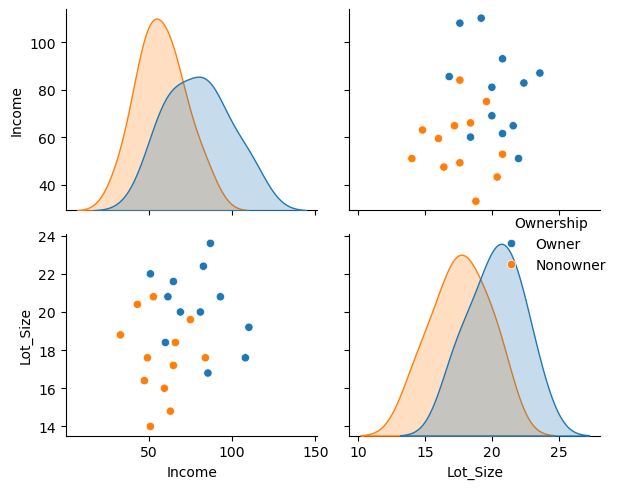

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.pairplot(data, hue = 'Ownership')
plt.tight_layout()

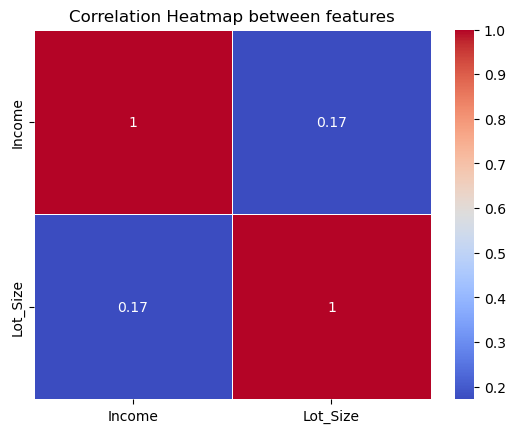

In [7]:
corr_matrix = data.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap ='coolwarm',linewidths = 0.5)
plt.title('Correlation Heatmap between features')
plt.show()

In [8]:
features = data.iloc[:, [0,1]]
covariance = features. cov()
covariance

,Income,Lot_Size
Income,391.768533,8.274130
Lot_Size,8.274130,5.896522


In [11]:
from sklearn import preprocessing
LE = preprocessing.LabelEncoder()

In [13]:
data['Ownership'] = LE.fit_transform(data['Ownership'])
data.head()

,Income,Lot_Size,Ownership
0,60.0,18.4,1
1,85.5,16.8,1
2,64.8,21.6,1
3,61.5,20.8,1
4,87.0,23.6,1


In [14]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(data)

,copy,True
,with_mean,True
,with_std,True


In [15]:
scaled_data = scaler.transform(data)
new_data = pd.DataFrame(scaled_data, columns = data.columns)
new_data.head()

,Income,Lot_Size,Ownership
0,-0.435452,-0.231370,1.0
1,0.880582,-0.904445,1.0
2,-0.187728,1.114781,1.0
3,-0.358039,0.778243,1.0
4,0.957995,1.956125,1.0


In [16]:
x = new_data.drop(columns='Ownership') # feature variable
y = new_data['Ownership'] # target variable

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=5)

In [20]:
#create  and Train LDA model
lda = LinearDiscriminantAnalysis()
lda.fit(x_train, y_train)

,solver,'svd'
,shrinkage,None
,priors,None
,n_components,None
,store_covariance,False
,tol,0.0001
,covariance_estimator,None


In [21]:
y_pred = lda.predict(x_test)

In [23]:
accuracy = accuracy_score(y_test, y_pred)
print(f'LDA Classification accuracy: {accuracy*100 :.2f}%')

LDA Classification accuracy: 100.00%


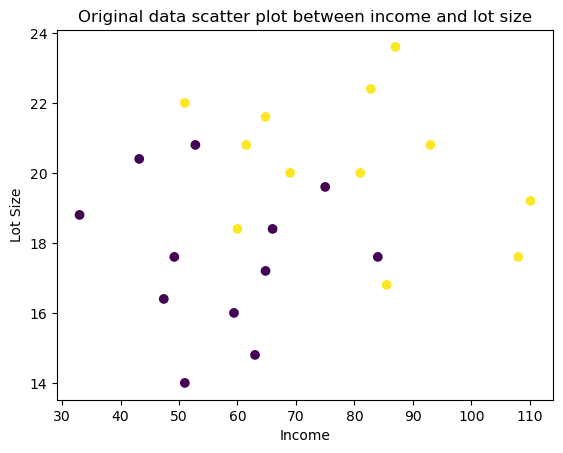

In [25]:
plt.scatter(data['Income'], data['Lot_Size'], c = data['Ownership'])
plt.xlabel('Income')
plt.ylabel('Lot Size')
plt.title('Original data scatter plot between income and lot size')
plt.show()

In [26]:
eigen_vectors = lda.scalings_
print(eigen_vectors)

[[0.91212707]
 [0.78254355]]


In [27]:
weights = lda.coef_
print("Feature Weights = ", weights)

Feature Weights =  [[1.63857506 1.40578696]]


In [28]:
intercept = lda. intercept_
print("Intercept for decision boundaries = ", intercept)

Intercept for decision boundaries =  [0.17886696]


In [29]:
variance_explained = lda.explained_variance_ratio_
print("Variance Explained by LDA components = ", variance_explained)

Variance Explained by LDA components =  [1.]


In [30]:
X_lda = lda.fit_transform(x, y)

In [31]:
print(X_lda)

[[-0.61750748]
 [ 0.01064948]
 [ 0.82951029]
 [ 0.36601756]
 [ 2.66407504]
 [ 2.1132957 ]
 [ 1.40432086]
 [ 2.00517105]
 [ 0.42575032]
 [ 1.8920919 ]
 [ 0.31275353]
 [ 1.00711197]
 [ 0.564622  ]
 [-0.05546964]
 [-0.84039023]
 [-0.6723681 ]
 [ 0.24159755]
 [-1.44435124]
 [-1.55743039]
 [-0.32682665]
 [-1.98698291]
 [-1.77376206]
 [-2.72342924]
 [-1.83844931]]


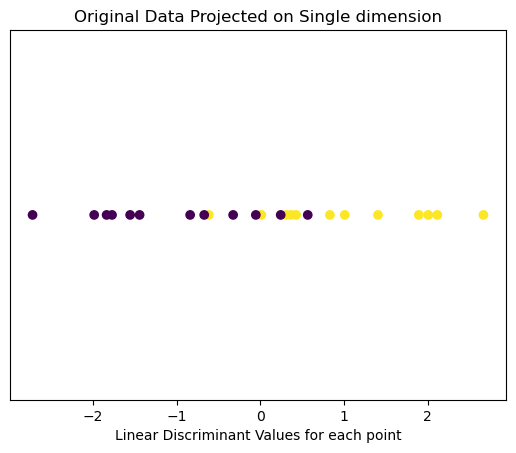

In [32]:
y_dummy = np.zeros_like(X_lda) # create dummy y variable for scatter plot
plt.scatter(X_lda, y_dummy, c= y)
plt.gca().get_yaxis().set_visible(False)
plt.xlabel("Linear Discriminant Values for each point")
plt.title("Original Data Projected on Single dimension")
plt.show()

In [ ]:
#CONCLUSION 
in todays class we have learned about feature extraction techinque called LDA ,in this method we reduced dimension that is we convert feature into single feature for better visualisation of graph and understanding of data .
    